# Dataset Hypothyroid

##  importation des bibliotheques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from scipy.io import arff
from sklearn.preprocessing import MinMaxScaler, StandardScaler

###  1-lire et afficher le dataset


In [2]:

data, meta= arff.loadarff("hypothyroid.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

display(df)

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,Class
0,41.0,F,f,f,f,f,f,f,f,f,...,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,...,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,...,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,...,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,...,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30.0,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,negative
3768,68.0,F,f,f,f,f,f,f,f,f,...,t,124.0,t,1.08,t,114.0,f,NaN,SVI,negative
3769,74.0,F,f,f,f,f,f,f,f,f,...,t,112.0,t,1.07,t,105.0,f,NaN,other,negative
3770,72.0,M,f,f,f,f,f,f,f,f,...,t,82.0,t,0.94,t,87.0,f,NaN,SVI,negative


### 2. Gestion des valeurs manquantes:

- Identification:

In [3]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)
#supprimer la colonne TBG car elle contient trop de valeurs manquantes
df = df.drop(columns=["TBG"])

['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'TBG']


- Remplacement

**Remarque:** l'attribut TBG contient seulement des valeurs nan donc on ne peut pas remplacer ses  valeurs avec moyenne ou mediane.

il faut premierement selectionner les valeurs numerique du dataset

In [4]:
# Selectionner a nouveau les attributs numeriques pour avoir les changements
numeriques_df = df.select_dtypes(include=np.number)

# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:
    if col not in df.columns:
        continue

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


#### Z-score :

In [5]:
# Sélectionner les attributs numériques après le nettoyage
numeriques_df = df.select_dtypes(include=np.number)

# Standardisation
scaler = StandardScaler()
scaled_dataset = scaler.fit_transform(numeriques_df)

# Convertir le résultat en DataFrame
scaled_dataset = pd.DataFrame(scaled_dataset, columns=numeriques_df.columns)

display(scaled_dataset)

,age,TSH,T3,TT4,T4U,FTI
0,-0.534665,-1.626075e-01,6.590677e-01,4.836103e-01,7.832271e-01,-0.046877
1,-1.431096,-4.237273e-02,-1.828839e-02,-1.832122e-01,-5.996931e-16,0.000000
2,-0.285657,-1.763487e-01,6.016131e-16,1.973375e-02,-4.591306e-01,0.303989
3,0.909584,-2.115603e-01,-1.537596e-01,1.933224e+00,-5.996931e-16,0.000000
4,0.909584,-1.875133e-01,-1.102058e+00,-1.371896e+00,-6.751928e-01,-1.290860
...,...,...,...,...,...,...
3767,-1.082484,-3.813927e-17,6.016131e-16,4.120051e-16,-5.996931e-16,0.000000
3768,0.809981,-1.754898e-01,1.171828e-01,4.546180e-01,4.591338e-01,0.112608
3769,1.108791,5.682774e-04,-2.892308e-01,1.067106e-01,4.051182e-01,-0.174465
3770,1.009188,-1.883721e-01,-1.828839e-02,-7.630579e-01,-2.970839e-01,-0.748611


### Courbe D'elbow

1. Calculer l'inertie pour chaque valeur de k

In [6]:
from sklearn.cluster import KMeans

inerties = []

# Tester k de 1 a 10
K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_dataset)

    inerties.append(kmeans.inertia_)

2. Tracer la courbe d'elbow

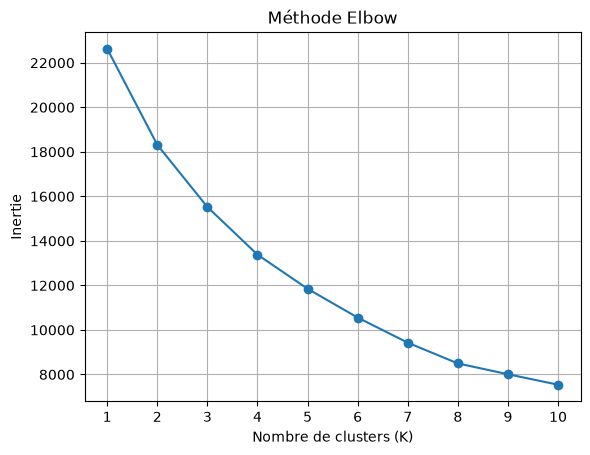

In [7]:
import matplotlib.pyplot as plt

plt.plot(K, inerties, marker='o')

plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode Elbow")

plt.xticks(K)
plt.grid()
plt.show()

### Algorithme KMeans

1. Application de l'algo

In [11]:
# selon le graphique, le nombre optimal de clusters est 4
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans.fit(scaled_dataset)

# Ajouter les clusters aux données
clusters = kmeans.labels_

print("Les clusters :", clusters)

Les clusters : [1 1 1 ... 0 0 0]


2. Afficher le nombre d'elements dans chaque cluster

In [12]:
print(pd.Series(clusters).value_counts().sort_index())

0    1829
1    1438
2     473
3      32
Name: count, dtype: int64


3. Coef de Silhouette

In [13]:
from sklearn.metrics import silhouette_score

score = silhouette_score(scaled_dataset, clusters)

print("Coefficient de silhouette :", score)

Coefficient de silhouette : 0.20745755449477757


4. Interpretation des resutats:

Le coefficient de silhouette permet d'évaluer la qualité du clustering en mesurant la cohésion des observations au sein de leurs clusters et la séparation entre les différents clusters.

Pour K = 4, le coefficient obtenu est de 0,207, ce qui indique une faible séparation entre les clusters.

En revanche, pour K = 3, le coefficient atteint 0,33. Cette amélioration indique une meilleure organisation des données en clusters, avec une séparation plus satisfaisante entre les groupes.

Ainsi, parmi ces deux configurations, K = 3 présente le meilleur résultat selon le coefficient de silhouette. Cependant, la qualité du clustering reste modérée et les groupes ne sont pas parfaitement séparés.